### Notebook 6b-1 — Second Case Study: Synthetic Tuberculosis Images with DC-GAN

> Trains two DC-GANs (one for tuberculosis, one for normal) **from scratch on the Shenzhen training set only** (201 tuberculosis and 195 normal images), generates the synthetic images, checks them, and saves them in the format needed by the classifier notebook. The architecture, the training loop and the checks are the same as in Notebook 3a (pneumonia).

**Input to attach**: the output of Notebook 6a (it contains `cache_tb/`). Turn on a **GPU**. Internet is not needed.

**Design decisions**

* **Training data = the Shenzhen `train` split** (396 images). Validation, test and Montgomery images are never used to train the generators. The `val` images are only used as a reference for the memorisation check.
* **Two unconditional DC-GANs**, one per class, so the class of every synthetic image is known by construction.
* **128 × 128 resolution**, with DiffAugment and EMA, exactly as in Notebook 3a. With only about 200 images per class a DC-GAN can memorise the training images, so the notebook includes a **memorisation check for every saved checkpoint** (section 6) to choose which checkpoint to use.
* **1,000 synthetic images per class** (5× the 201 real positives; in the pneumonia study it was 7×). Dose subsets are the first *k* images of each class (`index` < *k*).
* **Output for the classifier**: 224 × 224 arrays (Lanczos), like the rest of the pipeline.

**Saved** (`/kaggle/working`): `synthetic/dcgan/` (PNGs, manifest), `checkpoints/dcgan/`, and `cache_tb_syn/dcgan.npy` + `dcgan_index.csv`.

### 1. Configuration and Loading

In [1]:
import os, time, math, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision.utils import make_grid

SEED = 42
WORK = Path('/kaggle/working')
OUT_DIR, CKPT_DIR, SYN_CACHE = WORK / 'synthetic' / 'dcgan', WORK / 'checkpoints' / 'dcgan', WORK / 'cache_tb_syn'

IMG_SIZE = 128                       # 64 / 128 / 256 (must be a power of two)
NZ, NGF, NDF = 100, 64, 64
BATCH = 64
ITERS = {'pos': 15_000, 'neg': 15_000}     # fewer iterations than the pneumonia study: the training set is about 3 times smaller
N_SYN = {'pos': 1000, 'neg': 1000}   # synthetic images to generate per class
LR, BETAS, EMA_DECAY, REAL_LABEL = 2e-4, (0.5, 0.999), 0.999, 0.9
CKPT_EVERY, LOG_EVERY, RESUME = 2500, 200, True
for d in (OUT_DIR, CKPT_DIR, SYN_CACHE): d.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU (training will be very slow)')

# --- Locate the cache written by Notebook 6a ---
CACHE_TB = None
for cur, dirs, files in os.walk('/kaggle/input'):
    if 'train.npy' in files and 'train_index.csv' in files and 'val.npy' in files: CACHE_TB = Path(cur); break
assert CACHE_TB, 'cache_tb not found under /kaggle/input: attach the output of Notebook 6a via + Add Input'
print('CACHE_TB =', CACHE_TB)

Device: cuda | Tesla T4
CACHE_TB = /kaggle/input/notebooks/anamatemalas/06a-tb-data-preparation/cache_tb


### 2. Real Images

The 224 × 224 images of Notebook 6a are resized to 128 × 128 (Lanczos). Only the `train` split is used for training; `val` is kept as the hold-out reference.

In [2]:
def load_split(sp):
    X = np.load(CACHE_TB / f'{sp}.npy'); I = pd.read_csv(CACHE_TB / f'{sp}_index.csv'); assert len(X) == len(I)
    return X, I
to128 = lambda X: np.stack([np.asarray(Image.fromarray(a).resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS), dtype=np.uint8) for a in X])
Xtr, Itr = load_split('train'); Xva, Iva = load_split('val')
assert set(Itr['source']) == {'shenzhen'} and set(Iva['source']) == {'shenzhen'}, 'only Shenzhen images may be used here'
REAL = {'pos': to128(Xtr[Itr.label.values == 1]), 'neg': to128(Xtr[Itr.label.values == 0]),
        'val_pos': to128(Xva[Iva.label.values == 1]), 'val_neg': to128(Xva[Iva.label.values == 0])}
print({k: v.shape for k, v in REAL.items()})

{'pos': (201, 128, 128), 'neg': (195, 128, 128), 'val_pos': (51, 128, 128), 'val_neg': (49, 128, 128)}


### 3. Model Definitions

Identical to Notebook 3a: transposed-convolution generator, convolutional discriminator, differentiable augmentation (DiffAugment) on the discriminator inputs, and an EMA copy of the generator.

In [3]:
def conv_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

class Generator(nn.Module):
    def __init__(self, nz=NZ, ngf=NGF, nc=1, size=IMG_SIZE):
        super().__init__()
        depth = int(math.log2(size)) - 2                      # doublings from 4x4 to size
        ch = ngf * 2 ** (depth - 1)
        layers = [nn.ConvTranspose2d(nz, ch, 4, 1, 0, bias=False), nn.BatchNorm2d(ch), nn.ReLU(True)]
        for _ in range(depth - 1):
            layers += [nn.ConvTranspose2d(ch, ch // 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ch // 2), nn.ReLU(True)]
            ch //= 2
        layers += [nn.ConvTranspose2d(ch, nc, 4, 2, 1, bias=False), nn.Tanh()]
        self.net = nn.Sequential(*layers); self.apply(conv_init)
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, ndf=NDF, nc=1, size=IMG_SIZE):
        super().__init__()
        depth = int(math.log2(size)) - 2
        layers, ch = [nn.Conv2d(nc, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True)], ndf
        for _ in range(depth - 1):
            layers += [nn.Conv2d(ch, ch * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ch * 2), nn.LeakyReLU(0.2, True)]
            ch *= 2
        layers += [nn.Conv2d(ch, 1, 4, 1, 0, bias=False)]
        self.net = nn.Sequential(*layers); self.apply(conv_init)
    def forward(self, x): return self.net(x).view(-1)

def diffaug(x, translate=0.125, cutout=0.35):
    # Differentiable augmentation (Zhao et al., 2020): brightness, contrast, translation, cut-out
    B, _, S, _ = x.shape; dev = x.device
    x = x + (torch.rand(B, 1, 1, 1, device=dev) - 0.5) * 0.4
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * (torch.rand(B, 1, 1, 1, device=dev) * 0.5 + 0.75) + m
    sh = int(S * translate + 0.5)
    tx, ty = torch.randint(-sh, sh + 1, (B, 1, 1), device=dev), torch.randint(-sh, sh + 1, (B, 1, 1), device=dev)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=dev), torch.arange(S, device=dev), torch.arange(S, device=dev), indexing='ij')
    gx, gy = torch.clamp(gx + tx + 1, 0, S + 1), torch.clamp(gy + ty + 1, 0, S + 1)
    x = F.pad(x, [1, 1, 1, 1]).permute(0, 2, 3, 1).contiguous()[gb, gx, gy].permute(0, 3, 1, 2)
    cs = int(S * cutout + 0.5)
    ox, oy = torch.randint(0, S + (1 - cs % 2), (B, 1, 1), device=dev), torch.randint(0, S + (1 - cs % 2), (B, 1, 1), device=dev)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=dev), torch.arange(cs, device=dev), torch.arange(cs, device=dev), indexing='ij')
    gx, gy = torch.clamp(gx + ox - cs // 2, 0, S - 1), torch.clamp(gy + oy - cs // 2, 0, S - 1)
    mask = torch.ones(B, S, S, device=dev); mask[gb, gx, gy] = 0
    return x * mask.unsqueeze(1)

@torch.no_grad()
def ema_update(ema, model, decay):
    for pe, p in zip(ema.parameters(), model.parameters()): pe.lerp_(p, 1 - decay)
    for be, b in zip(ema.buffers(), model.buffers()): be.copy_(b)

print('G params: %.1fM | D params: %.1fM' % (sum(p.numel() for p in Generator().parameters()) / 1e6,
                                             sum(p.numel() for p in Discriminator().parameters()) / 1e6))

G params: 12.8M | D params: 11.2M


### 4. Training Loop

Identical to Notebook 3a. A checkpoint of the EMA generator is saved every `CKPT_EVERY` iterations.

In [4]:
bce = nn.BCEWithLogitsLoss()

def to_tensor(u8):                                   # uint8 (N,H,W) -> float [-1,1] (N,1,H,W)
    return torch.from_numpy(u8).float().div(127.5).sub(1).unsqueeze(1)

def save_grid(x, path, nrow=8):
    g = make_grid(x.cpu(), nrow=nrow, normalize=True, value_range=(-1, 1), padding=2)
    Image.fromarray((g[0].numpy() * 255).astype(np.uint8)).save(path)

def train_dcgan(name, real_u8, iters):
    set_seed(SEED)
    data = to_tensor(real_u8).to(DEVICE); N = len(data)
    G, D = Generator().to(DEVICE), Discriminator().to(DEVICE)
    G_ema = Generator().to(DEVICE); G_ema.load_state_dict(G.state_dict()); G_ema.eval()
    oG = torch.optim.Adam(G.parameters(), LR, betas=BETAS); oD = torch.optim.Adam(D.parameters(), LR, betas=BETAS)
    fixed_z = torch.randn(64, NZ, 1, 1, generator=torch.Generator().manual_seed(SEED)).to(DEVICE)
    hist, start = [], 0
    last = CKPT_DIR / f'{name}_last.pt'
    if RESUME and last.exists():
        ck = torch.load(last, map_location=DEVICE)
        G.load_state_dict(ck['G']); D.load_state_dict(ck['D']); G_ema.load_state_dict(ck['G_ema'])
        oG.load_state_dict(ck['oG']); oD.load_state_dict(ck['oD']); hist, start = ck['hist'], ck['it']
        print(f'[{name}] resumed from iteration {start}')
    (OUT_DIR / 'samples').mkdir(exist_ok=True)
    t0 = time.time()
    for it in range(start, iters):
        real = data[torch.randint(0, N, (BATCH,), device=DEVICE)]
        z = torch.randn(BATCH, NZ, 1, 1, device=DEVICE)
        fake = G(z)
        # --- Discriminator ---
        d_real, d_fake = D(diffaug(real)), D(diffaug(fake.detach()))
        lD = bce(d_real, torch.full_like(d_real, REAL_LABEL)) + bce(d_fake, torch.zeros_like(d_fake))
        oD.zero_grad(set_to_none=True); lD.backward(); oD.step()
        # --- Generator (non-saturating loss) ---
        g_out = D(diffaug(fake))
        lG = bce(g_out, torch.ones_like(g_out))
        oG.zero_grad(set_to_none=True); lG.backward(); oG.step()
        ema_update(G_ema, G, min(EMA_DECAY, (1 + it) / (10 + it)))
        if (it + 1) % LOG_EVERY == 0:
            hist.append((it + 1, lD.item(), lG.item(), torch.sigmoid(d_real).mean().item(), torch.sigmoid(d_fake).mean().item()))
        if (it + 1) % CKPT_EVERY == 0 or it + 1 == iters:
            with torch.no_grad(): save_grid(G_ema(fixed_z), OUT_DIR / 'samples' / f'{name}_it{it + 1:06d}.png')
            ck = {'G': G.state_dict(), 'D': D.state_dict(), 'G_ema': G_ema.state_dict(), 'oG': oG.state_dict(),
                  'oD': oD.state_dict(), 'hist': hist, 'it': it + 1}
            torch.save(ck, last); torch.save(G_ema.state_dict(), CKPT_DIR / f'{name}_ema_it{it + 1:06d}.pt')
            print(f'[{name}] it {it + 1:6d}/{iters} | lD {lD.item():.3f} lG {lG.item():.3f} | '
                  f'D(real) {hist[-1][3]:.2f} D(fake) {hist[-1][4]:.2f} | {(time.time() - t0) / 60:.1f} min')
    torch.save(G_ema.state_dict(), CKPT_DIR / f'{name}_ema_final.pt')
    return pd.DataFrame(hist, columns=['it', 'loss_D', 'loss_G', 'D_real', 'D_fake'])

### 5. Train the Two DC-GANs

Tuberculosis first, then normal. If the session is interrupted, running the cell again resumes from the last checkpoint (`RESUME = True`).

In [5]:
hist_pos = train_dcgan('pos', REAL['pos'], ITERS['pos'])

[pos] it   2500/15000 | lD 1.551 lG 1.355 | D(real) 0.67 D(fake) 0.39 | 15.3 min
[pos] it   5000/15000 | lD 1.448 lG 0.958 | D(real) 0.34 D(fake) 0.19 | 30.5 min
[pos] it   7500/15000 | lD 0.471 lG 5.421 | D(real) 0.71 D(fake) 0.11 | 45.7 min
[pos] it  10000/15000 | lD 0.518 lG 6.217 | D(real) 0.67 D(fake) 0.00 | 60.9 min
[pos] it  12500/15000 | lD 1.027 lG 1.274 | D(real) 0.41 D(fake) 0.00 | 76.2 min
[pos] it  15000/15000 | lD 1.230 lG 1.808 | D(real) 0.66 D(fake) 0.46 | 91.4 min


In [6]:
hist_neg = train_dcgan('neg', REAL['neg'], ITERS['neg'])

[neg] it   2500/15000 | lD 0.690 lG 2.339 | D(real) 0.60 D(fake) 0.03 | 15.2 min
[neg] it   5000/15000 | lD 1.605 lG 0.663 | D(real) 0.25 D(fake) 0.08 | 30.4 min
[neg] it   7500/15000 | lD 0.654 lG 3.074 | D(real) 0.53 D(fake) 0.15 | 45.7 min
[neg] it  10000/15000 | lD 1.039 lG 1.581 | D(real) 0.57 D(fake) 0.24 | 60.9 min
[neg] it  12500/15000 | lD 0.749 lG 2.448 | D(real) 0.69 D(fake) 0.19 | 76.1 min
[neg] it  15000/15000 | lD 0.601 lG 3.031 | D(real) 0.89 D(fake) 0.18 | 91.3 min


### 6. Which Checkpoint? Memorisation Check

With about 200 training images the generator can start to reproduce the training images instead of creating new ones. For every saved checkpoint, 200 images are generated and each is compared (32 × 32 pixel distance) with its nearest **training** image; the same is done for the **validation** images, which the generator never saw. If the synthetic images are much closer to the training set than the validation images are, the checkpoint is memorising. Pick the latest checkpoint where the ratio is not clearly below 1 and the images still look good, and write it in `CKPT_CHOICE`.

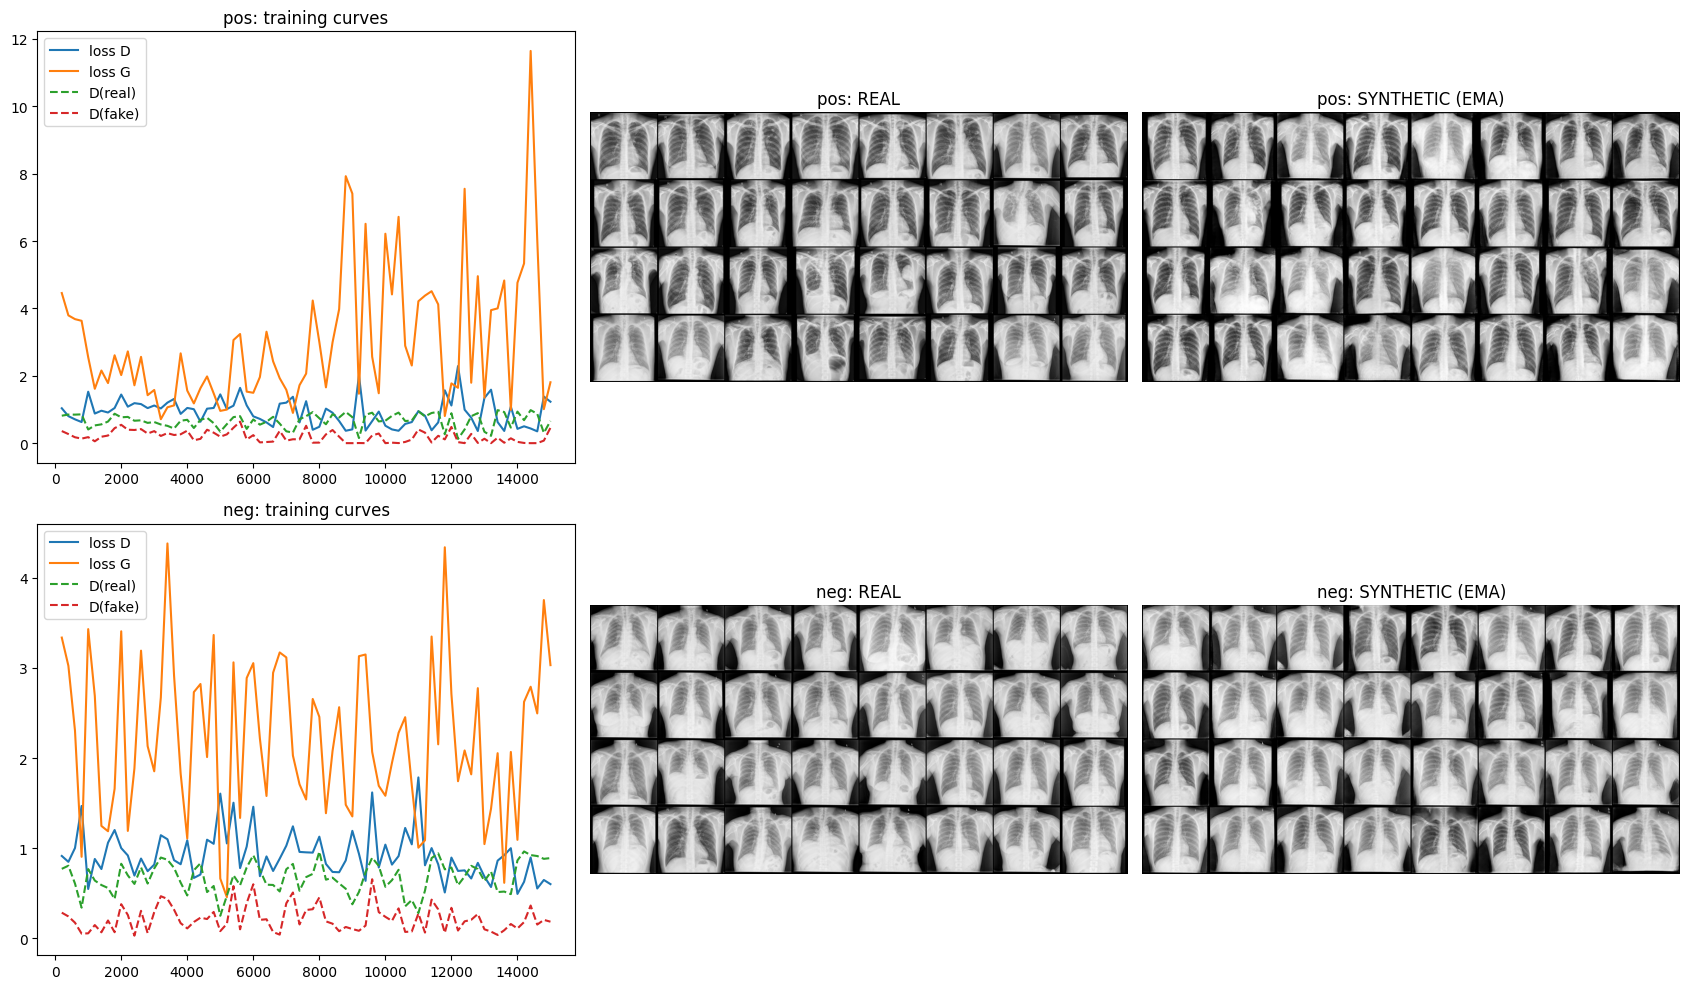

In [7]:
@torch.no_grad()
def load_ema(name, ckpt=None):
    G = Generator().to(DEVICE); G.load_state_dict(torch.load(CKPT_DIR / (ckpt or f'{name}_ema_final.pt'), map_location=DEVICE)); return G.eval()

@torch.no_grad()
def sample(G, n, seed, bs=250):
    g = torch.Generator(device=DEVICE).manual_seed(seed); out = []
    for i in range(0, n, bs):
        z = torch.randn(min(bs, n - i), NZ, 1, 1, device=DEVICE, generator=g)
        out.append(((G(z).clamp(-1, 1) + 1) * 127.5).round().byte().squeeze(1).cpu())
    return torch.cat(out).numpy()

def u8_grid(arr, n=32, nrow=8):
    x = torch.from_numpy(arr[:n]).float().unsqueeze(1) / 255
    return make_grid(x, nrow=nrow, padding=2)[0].numpy()

fig, ax = plt.subplots(2, 3, figsize=(17, 10))
for r, (name, h) in enumerate([('pos', hist_pos), ('neg', hist_neg)]):
    ax[r, 0].plot(h.it, h.loss_D, label='loss D'); ax[r, 0].plot(h.it, h.loss_G, label='loss G')
    ax[r, 0].plot(h.it, h.D_real, '--', label='D(real)'); ax[r, 0].plot(h.it, h.D_fake, '--', label='D(fake)')
    ax[r, 0].set_title(f'{name}: training curves'); ax[r, 0].legend()
    ax[r, 1].imshow(u8_grid(REAL[name]), cmap='gray'); ax[r, 1].set_title(f'{name}: REAL'); ax[r, 1].axis('off')
    ax[r, 2].imshow(u8_grid(sample(load_ema(name), 32, SEED)), cmap='gray'); ax[r, 2].set_title(f'{name}: SYNTHETIC (EMA)'); ax[r, 2].axis('off')
plt.tight_layout(); plt.show()

In [8]:
def small(u8, s=32): return F.adaptive_avg_pool2d(torch.from_numpy(u8).float().unsqueeze(1) / 255, s).flatten(1)
def nn_dist(q, ref, chunk=500): return torch.cat([torch.cdist(q[i:i + chunk], ref).min(1).values for i in range(0, len(q), chunk)])
rows = []
for cls in ('pos', 'neg'):
    tr, va = small(REAL[cls]), small(REAL['val_' + cls]); d_val = nn_dist(va, tr).median().item()
    for p in sorted(CKPT_DIR.glob(f'{cls}_ema_it*.pt')):
        G = load_ema(cls, p.name); d_syn = nn_dist(small(sample(G, 200, SEED)), tr)
        rows.append({'class': cls, 'checkpoint': p.name, 'syn->train median': d_syn.median().item(), 'val->train median': d_val,
                     'ratio (1 = as far as unseen real images)': d_syn.median().item() / d_val})
ck = pd.DataFrame(rows); print(ck.round(3).to_string(index=False))

class          checkpoint  syn->train median  val->train median  ratio (1 = as far as unseen real images)
  pos pos_ema_it002500.pt              3.803              3.382                                     1.125
  pos pos_ema_it005000.pt              3.653              3.382                                     1.080
  pos pos_ema_it007500.pt              3.721              3.382                                     1.100
  pos pos_ema_it010000.pt              3.819              3.382                                     1.129
  pos pos_ema_it012500.pt              3.690              3.382                                     1.091
  pos pos_ema_it015000.pt              3.754              3.382                                     1.110
  neg neg_ema_it002500.pt              3.489              3.379                                     1.032
  neg neg_ema_it005000.pt              3.261              3.379                                     0.965
  neg neg_ema_it007500.pt              3.187  

In [9]:
CKPT_CHOICE = {'pos': None, 'neg': None}      # for example {'pos': 'pos_ema_it010000.pt', 'neg': 'pos_ema_it012500.pt'}; None = the last (final) checkpoint

### 7. Generate the Synthetic Dataset

1,000 images per class with the chosen checkpoint, a fixed seed per class, saved as PNG (128 × 128) and as a manifest. `index` allows the dose subsets (the first 250, 500, 1,000 images).

In [10]:
SYN, rows = {}, []
for cls, label, seed in [('pos', 1, SEED), ('neg', 0, SEED + 1)]:
    G = load_ema(cls, CKPT_CHOICE[cls]); arr = sample(G, N_SYN[cls], seed); SYN[cls] = arr
    d = OUT_DIR / ('tuberculosis' if label else 'normal'); d.mkdir(exist_ok=True)
    np.save(OUT_DIR / f'dcgan_{cls}_{IMG_SIZE}.npy', arr)
    for i, a in enumerate(arr):
        fn = f'dcgan_{cls}_{i:05d}.png'; Image.fromarray(a, 'L').save(d / fn)
        rows.append({'image': fn, 'path': str(d / fn), 'label': label, 'source': 'synthetic', 'generator': 'dcgan', 'img_size': IMG_SIZE,
                     'gen_seed': seed, 'index': i, 'checkpoint': CKPT_CHOICE[cls] or f'{cls}_ema_final.pt'})
manifest = pd.DataFrame(rows); manifest.to_csv(OUT_DIR / 'dcgan_manifest.csv', index=False)
print(manifest.groupby('label').size().rename('images'))

label
0    1000
1    1000
Name: images, dtype: int64


### 8. Screening Checks

Same checks as Notebook 3a: pixel intensity (mean, std) of real and synthetic images, and the synthetic images that are closest to a training image next to that image.

Pixel intensity (mean, std) per class:
                      pos            neg
real_train  (142.3, 73.1)  (153.6, 70.7)
synthetic   (143.5, 76.8)  (153.2, 68.6)


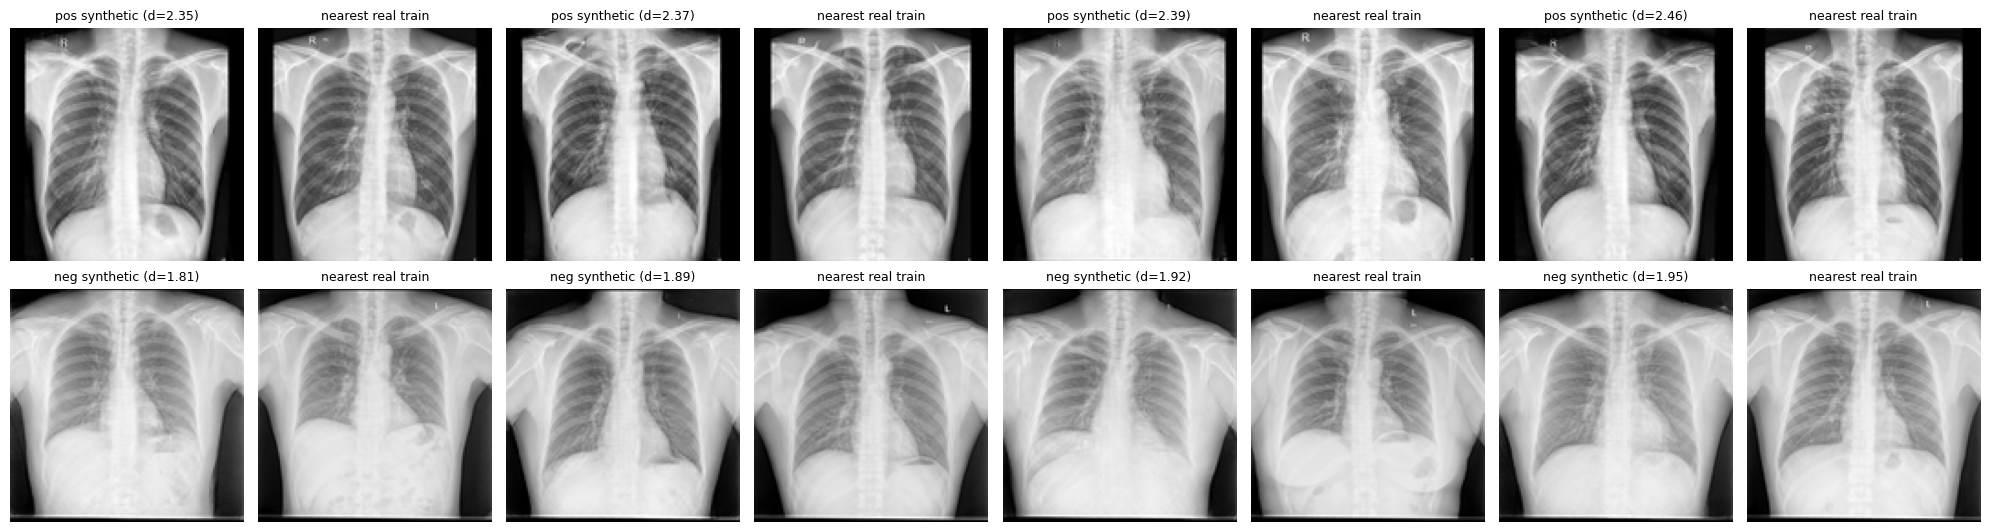

class  syn->train median  val->train median  syn->train p1  val->train p1  % syn closer than val p1
  pos              3.781              3.382          2.610          2.651                       1.5
  neg              3.275              3.379          2.066          2.145                       2.0


In [11]:
stats = pd.DataFrame({
    'real_train':   {c: (REAL[c].mean(), REAL[c].std()) for c in ['pos', 'neg']},
    'synthetic':    {c: (SYN[c].mean(), SYN[c].std()) for c in ['pos', 'neg']}}).T
print('Pixel intensity (mean, std) per class:'); print(stats.map(lambda t: tuple(round(v, 1) for v in t)))

def small(u8, s=32):
    return F.adaptive_avg_pool2d(torch.from_numpy(u8).float().unsqueeze(1) / 255, s).flatten(1)

def nn_dist(q, ref, chunk=1000):
    return torch.cat([torch.cdist(q[i:i + chunk], ref).min(1).values for i in range(0, len(q), chunk)])

fig, ax = plt.subplots(2, 8, figsize=(20, 5.5)); res = []
for r, (cls, vref) in enumerate([('pos', 'val_pos'), ('neg', 'val_neg')]):
    tr, syn, val = small(REAL[cls]), small(SYN[cls]), small(REAL[vref])
    d_syn, d_val = nn_dist(syn, tr), nn_dist(val, tr)
    res.append({'class': cls, 'syn->train median': d_syn.median().item(), 'val->train median': d_val.median().item(),
                'syn->train p1': d_syn.quantile(0.01).item(), 'val->train p1': d_val.quantile(0.01).item(),
                '% syn closer than val p1': 100 * (d_syn < d_val.quantile(0.01)).float().mean().item()})
    idx = d_syn.argsort()[:4]; nn_idx = torch.cdist(syn[idx], tr).argmin(1)
    for k in range(4):
        ax[r, 2 * k].imshow(SYN[cls][idx[k]], cmap='gray'); ax[r, 2 * k].set_title(f'{cls} synthetic (d={d_syn[idx[k]]:.2f})', fontsize=9)
        ax[r, 2 * k + 1].imshow(REAL[cls][nn_idx[k]], cmap='gray'); ax[r, 2 * k + 1].set_title('nearest real train', fontsize=9)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()
print(pd.DataFrame(res).round(3).to_string(index=False))

### 9. Export for the Classifier

Synthetic images are resized from 128 to 224 pixels with Lanczos resampling (as in the pneumonia pipeline) and saved as one array with an index sorted by class (tuberculosis first) and `index`.

In [12]:
man = manifest.sort_values(['label', 'index'], ascending=[False, True]).reset_index(drop=True)
X224 = np.stack([np.asarray(Image.open(p).convert('L').resize((224, 224), Image.Resampling.LANCZOS), dtype=np.uint8) for p in man['path']])
np.save(SYN_CACHE / 'dcgan.npy', X224); man.drop(columns=['path']).to_csv(SYN_CACHE / 'dcgan_index.csv', index=False)
total = sum(f.stat().st_size for f in WORK.rglob('*') if f.is_file() and 'checkpoints' not in f.parts) / 1e6
print(X224.shape, X224.dtype, f'| output without checkpoints: {total:.0f} MB'); print(sorted(p.name for p in SYN_CACHE.iterdir()))

(2000, 224, 224) uint8 | output without checkpoints: 161 MB
['dcgan.npy', 'dcgan_index.csv']
